# 1.0 — Initial Data Exploration

**Case**: Credit granting policy review for a Fintech client (Klavi).

**Goal of this notebook**: first contact with the raw data — schemas, keys, coverage, data quality, target definition — before any feature analysis or modeling.

**Inputs** (`data/raw/`):
- `profile_case_credit.parquet` — despite the name, holds **performance data**: `uuid`, `DATA`, `SAFRA` (vintage), `OVER30M2` (default flag: over 30 days past due in first 2 months), `STATUS`
- `transactions_case_credit.parquet` — despite the name, holds **application features**: Klavi scores, social class, employment status, region, income, betting-risk, financial capacity

**Questions to answer here**:
1. What is the grain of each table? Is `uuid` a unique key?
2. How well do the two tables join (coverage / orphans)?
3. What does the target `OVER30M2` look like — overall rate and by `SAFRA` (vintage stability)?
4. Data quality: missingness, duplicates, suspicious values, dtypes to fix

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"

PROFILE_PATH = RAW_DIR / "profile_case_credit.parquet" # performance data
TRANSACTIONS_PATH = RAW_DIR / "transactions_case_credit.parquet" # application features

## 1. Load raw data

In [2]:
perf = pd.read_parquet(PROFILE_PATH)      # performance / target table
feat = pd.read_parquet(TRANSACTIONS_PATH)  # features table

# drop leftover pandas index column if present
feat = feat.drop(columns=[c for c in feat.columns if c.startswith("__index_level")])

print(f"perf: {perf.shape[0]:,} rows x {perf.shape[1]} cols")
print(f"feat: {feat.shape[0]:,} rows x {feat.shape[1]} cols")

perf: 220,618 rows x 5 cols
feat: 371,596 rows x 10 cols


In [3]:
perf.head()

,uuid,DATA,SAFRA,OVER30M2,STATUS
0,d946dabe8351c29c3ca9db3c7005341b,2024-08-24,202408.0,0.0,Contratado
1,b9aa3d3552e2e21f92d34df2540de5c3,2024-09-02,202409.0,1.0,Contratado
2,ac5371c706da6f7a57c9b9593a8a5d04,2024-11-25,202411.0,0.0,Contratado
3,d44880bed90eaacb2fba3feead83ca16,2024-09-09,202409.0,0.0,Contratado
4,8ec0eefeda7ae58d5a98a2d59aca4bbb,2024-06-18,202406.0,0.0,Contratado


In [4]:
feat.head()

,uuid,REFERENCIA,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira
0,7b0c9b36fe0f730f7c0d081534ff9a2b,2024-06-12,58.07,512.0,D/E,Desconhecido,Sudeste,1052.65,0.0,839.64
3,513b46119c7d33fc324f3c561905c159,2025-02-06,NaN,422.0,C,Desconhecido,Sudeste,NaN,NaN,2213.37
7,0d7fed4a5b92cbae24e2b80e49fb0a4e,2025-06-13,NaN,607.0,C,Desconhecido,Sudeste,NaN,NaN,587.04
8,c158eeca94b81f5f63cee1496dbea081,2024-07-30,NaN,NaN,C,Autônomo,Sudeste,NaN,NaN,1961.59
9,97ebff4ac03d546fcb03040d1866bea0,2024-11-04,NaN,533.0,B,Desconhecido,Sudeste,NaN,NaN,3585.16


## 2. Grain and keys

Is `uuid` unique in each table? If not, what does a duplicated `uuid` mean (multiple applications, multiple vintages, pure duplicates)?

In [5]:
for name, df in [("perf", perf), ("feat", feat)]:
    n = len(df)
    n_uuid = df["uuid"].nunique()
    n_dup_rows = df.duplicated().sum()
    print(f"{name}: rows={n:,}  unique uuid={n_uuid:,}  fully-duplicated rows={n_dup_rows:,}")

perf: rows=220,618  unique uuid=184,009  fully-duplicated rows=0


feat: rows=371,596  unique uuid=96,196  fully-duplicated rows=0


In [6]:
# inspect a few uuids that repeat, in each table
dup_uuid_perf = perf[perf["uuid"].duplicated(keep=False)].sort_values("uuid")
dup_uuid_feat = feat[feat["uuid"].duplicated(keep=False)].sort_values("uuid")
print(f"perf rows with repeated uuid: {len(dup_uuid_perf):,}")
print(f"feat rows with repeated uuid: {len(dup_uuid_feat):,}")
dup_uuid_feat.head(10)

perf rows with repeated uuid: 55,840
feat rows with repeated uuid: 333,361


,uuid,REFERENCIA,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira
33864,000007d320ee2155609c8f68d640580e,2024-08-30,NaN,503.0,C,Autônomo,Centro-Oeste,NaN,NaN,379.66
1088937,000007d320ee2155609c8f68d640580e,2025-04-14,NaN,519.0,C,Autônomo,Centro-Oeste,NaN,NaN,379.66
1131442,000007d320ee2155609c8f68d640580e,2025-06-16,NaN,522.0,C,Autônomo,Centro-Oeste,NaN,NaN,379.66
1152476,000007d320ee2155609c8f68d640580e,2024-09-02,NaN,503.0,C,Autônomo,Centro-Oeste,NaN,NaN,379.66
1166447,000007d320ee2155609c8f68d640580e,2024-08-29,NaN,503.0,C,Autônomo,Centro-Oeste,NaN,NaN,379.66
35309,0000a44412130417e32cb76ef45bf57e,2024-07-26,NaN,NaN,C,Formal,Norte,NaN,NaN,2041.63
35310,0000a44412130417e32cb76ef45bf57e,2024-10-02,NaN,NaN,C,Formal,Norte,NaN,NaN,2041.63
1014036,0004296acd24fc8a5abaee0abf6df60a,2025-06-30,NaN,434.0,C,Formal,Sudeste,NaN,NaN,2577.90
1014037,0004296acd24fc8a5abaee0abf6df60a,2024-09-19,NaN,393.0,C,Formal,Sudeste,NaN,NaN,2577.90
1014038,0004296acd24fc8a5abaee0abf6df60a,2025-06-11,NaN,434.0,C,Formal,Sudeste,NaN,NaN,2577.90


## 3. Join coverage

How many uuids exist in both tables? Orphans on either side reduce the usable sample and may bias it.

In [7]:
perf_ids = set(perf["uuid"])
feat_ids = set(feat["uuid"])

both = perf_ids & feat_ids
only_perf = perf_ids - feat_ids
only_feat = feat_ids - perf_ids

print(f"uuids in both:      {len(both):,}")
print(f"only in perf:       {len(only_perf):,} ({len(only_perf)/len(perf_ids):.1%} of perf)")
print(f"only in feat:       {len(only_feat):,} ({len(only_feat)/len(feat_ids):.1%} of feat)")

uuids in both:      96,196
only in perf:       87,813 (47.7% of perf)
only in feat:       0 (0.0% of feat)


## 4. Target: `OVER30M2`

Overall default rate, missing target rows, and rate by `SAFRA` (vintage) — a stable target across vintages is a precondition for pooling them in one model.

In [8]:
print(perf["OVER30M2"].value_counts(dropna=False))
print(f"\noverall default rate (non-missing): {perf['OVER30M2'].mean():.2%}")
print(f"missing target: {perf['OVER30M2'].isna().mean():.2%}")
print("\nSTATUS breakdown:")
print(perf["STATUS"].value_counts(dropna=False))

OVER30M2
NaN    196470
0.0     21660
1.0      2488
Name: count, dtype: int64

overall default rate (non-missing): 10.30%
missing target: 89.05%

STATUS breakdown:
STATUS
Reprovado     119247
Aprovado       77223
Contratado     24148
Name: count, dtype: int64


In [9]:
# how does STATUS relate to having a target? (e.g. rejected apps may have no performance)
pd.crosstab(perf["STATUS"], perf["OVER30M2"].isna(), dropna=False)

OVER30M2,False,True
STATUS,,
Aprovado,0,77223
Contratado,24148,0
Reprovado,0,119247


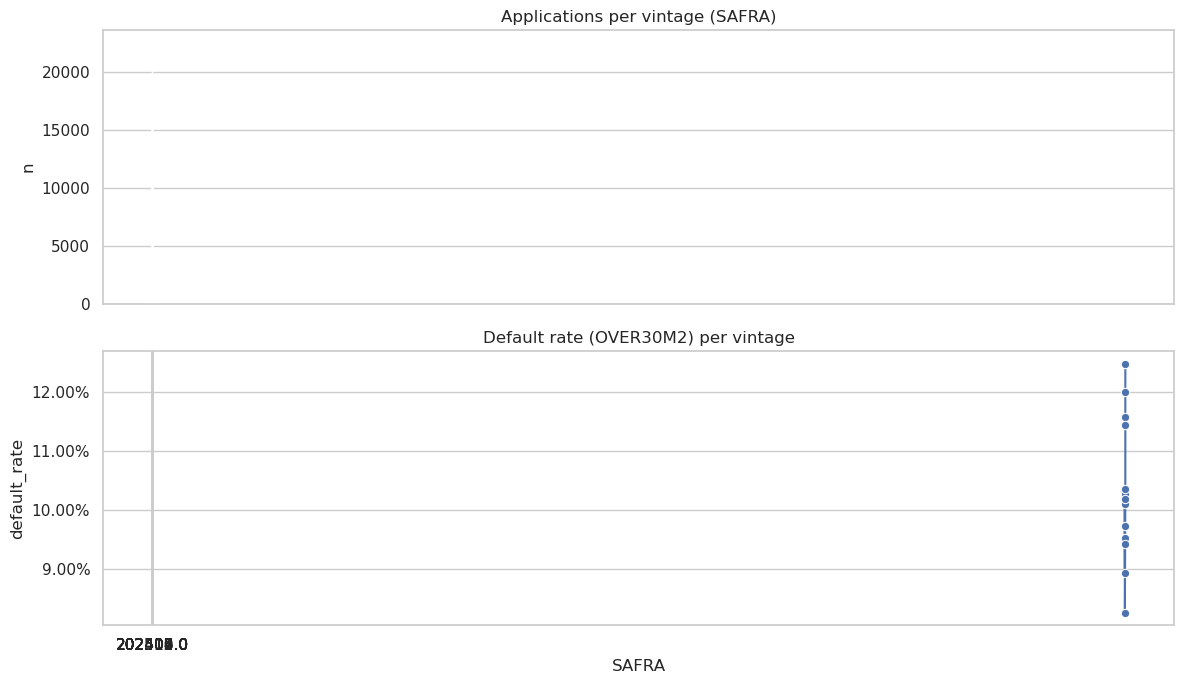

,SAFRA,n,default_rate
0,202406.0,15683,0.101005
1,202407.0,17011,0.089351
2,202408.0,17408,0.102667
3,202409.0,16678,0.097341
4,202410.0,18800,0.095330
5,202411.0,22498,0.094212
6,202412.0,16256,0.082569
7,202501.0,18049,0.101800
8,202502.0,15469,0.103488
9,202503.0,15607,0.115712


In [10]:
by_safra = (
    perf.groupby("SAFRA", dropna=False)
    .agg(n=("uuid", "size"), default_rate=("OVER30M2", "mean"))
    .reset_index()
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sns.barplot(data=by_safra, x="SAFRA", y="n", ax=axes[0], color="steelblue")
axes[0].set_title("Applications per vintage (SAFRA)")
sns.lineplot(data=by_safra, x="SAFRA", y="default_rate", ax=axes[1], marker="o")
axes[1].set_title("Default rate (OVER30M2) per vintage")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

by_safra

## 5. Data quality — missingness and dtypes

In [11]:
def quality_report(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })

quality_report(perf)

,dtype,n_missing,pct_missing,n_unique
uuid,str,0,0.00,184009
DATA,str,0,0.00,385
SAFRA,float64,0,0.00,13
OVER30M2,float64,196470,89.05,2
STATUS,str,0,0.00,3


In [12]:
quality_report(feat)

,dtype,n_missing,pct_missing,n_unique
uuid,str,0,0.00,96196
REFERENCIA,str,0,0.00,385
score_klavi_1,float64,339319,91.31,1458
score_klavi_2,float64,40023,10.77,319
classe_social,str,0,0.00,4
status_empregaticio,str,0,0.00,5
regiao,str,583,0.16,5
Renda,float64,339319,91.31,4913
risco_aposta,float64,339319,91.31,11
Capacidade Financeira,float64,46310,12.46,70497


In [13]:
# DATA is a string — check its format and whether it is consistent with SAFRA
perf["DATA"].head(10).tolist()

['2024-08-24',
 '2024-09-02',
 '2024-11-25',
 '2024-09-09',
 '2024-06-18',
 '2024-09-07',
 '2024-11-19',
 '2025-05-28',
 '2025-05-08',
 '2025-06-20']

## 6. Feature distributions

### 6.1 Numeric features

In [14]:
num_cols = feat.select_dtypes(include="number").columns.tolist()
feat[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
score_klavi_1,32277.0,-72475.672167,259379.346501,-999999.00,40.34,57.25,68.19,100.00
score_klavi_2,331573.0,520.963981,60.696365,345.00,481.00,524.00,566.00,663.00
Renda,32277.0,2850.452457,3600.016877,317.28,1321.57,2066.94,3057.77,129296.19
risco_aposta,32277.0,1.412585,2.739815,0.00,0.00,0.00,1.00,10.00
Capacidade Financeira,325286.0,1925.910835,5038.807631,-1088144.71,803.83,1470.81,2361.59,120795.85


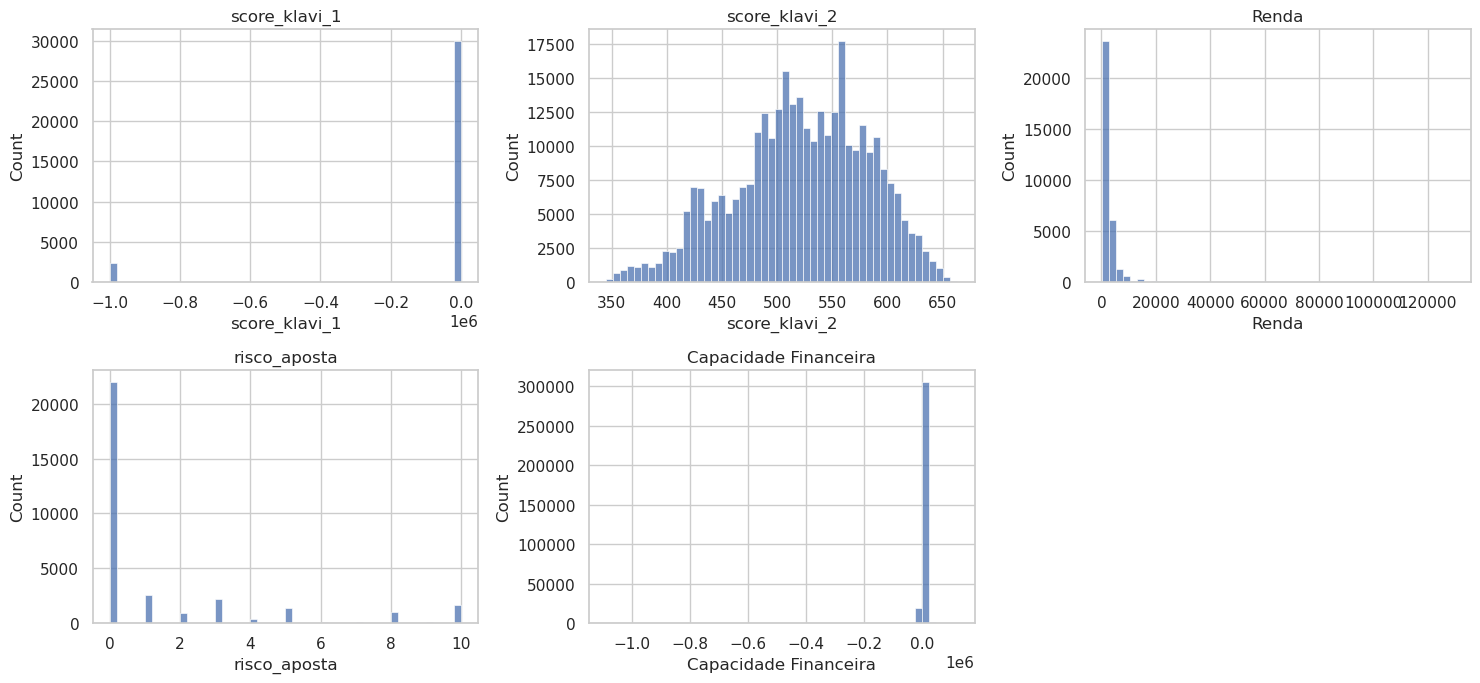

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(feat[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### 6.2 Categorical features

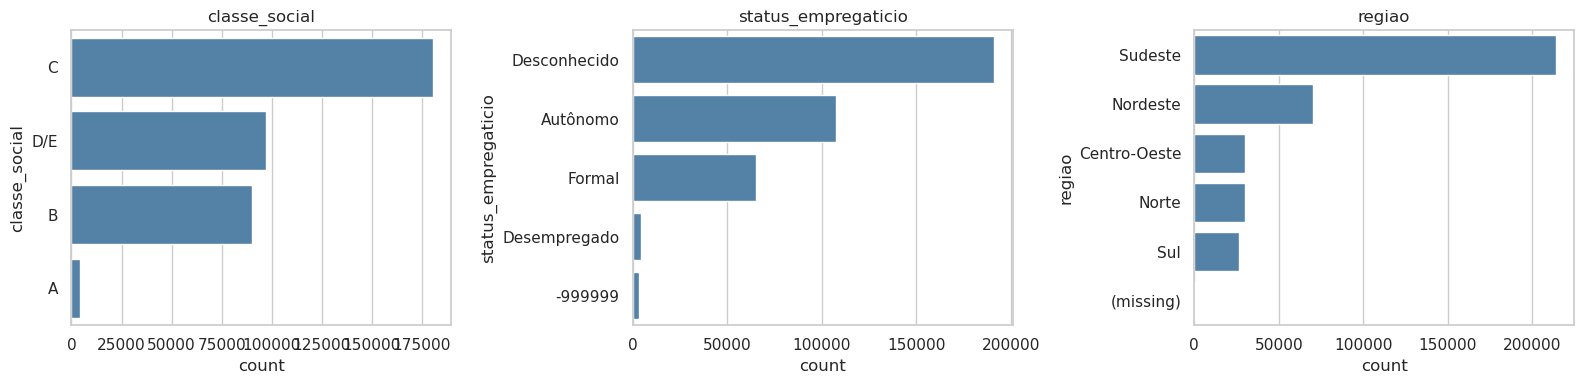

In [16]:
cat_cols = ["classe_social", "status_empregaticio", "regiao"]
feat_plot = feat[cat_cols].fillna("(missing)")
fig, axes = plt.subplots(1, len(cat_cols), figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    order = feat_plot[col].value_counts().index
    sns.countplot(data=feat_plot, y=col, order=order, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7. First look at features vs target

Quick signal check on the joined sample — proper feature analysis (IV/WoE, correlations, leakage checks) goes in a later notebook.

In [17]:
df = perf.merge(feat, on="uuid", how="inner")
labeled = df[df["OVER30M2"].notna()].copy()
print(f"joined rows: {len(df):,}   with target: {len(labeled):,}")

joined rows: 1,376,327   with target: 55,610


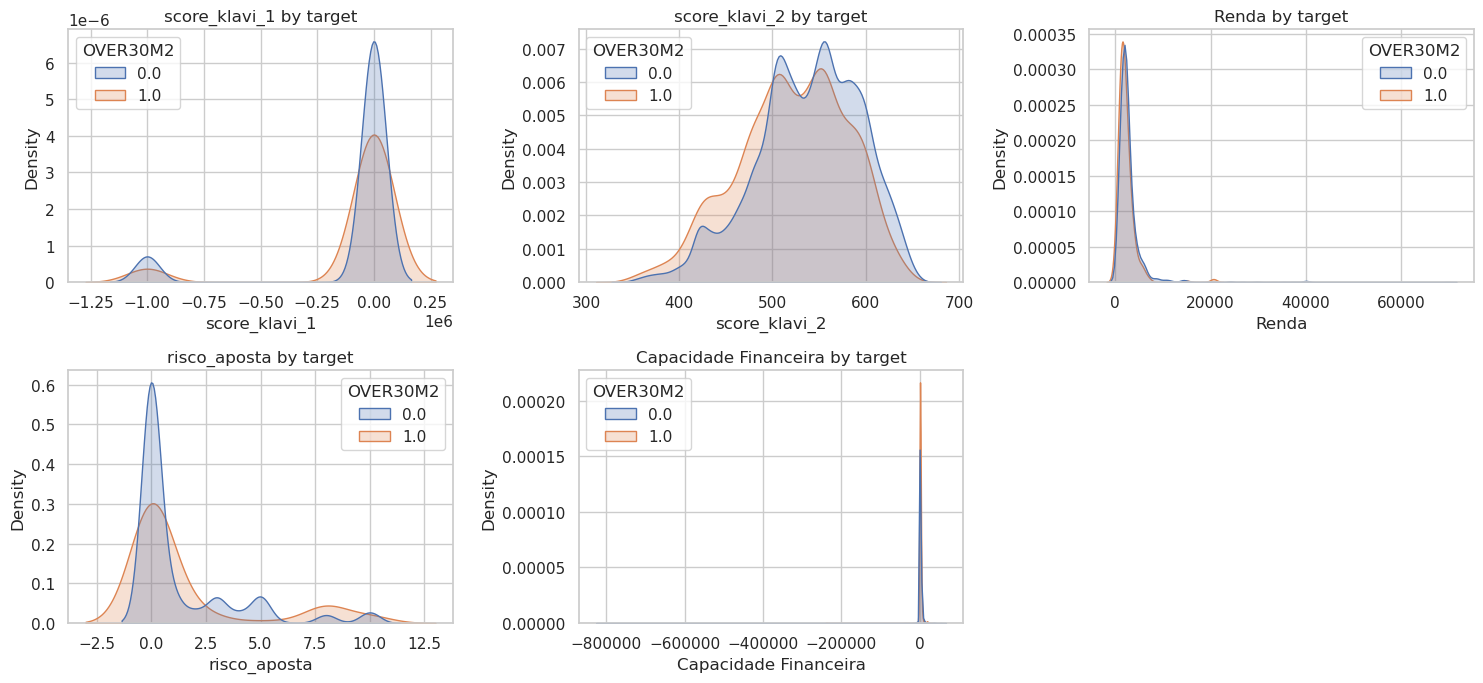

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.kdeplot(data=labeled, x=col, hue="OVER30M2", common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} by target")
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

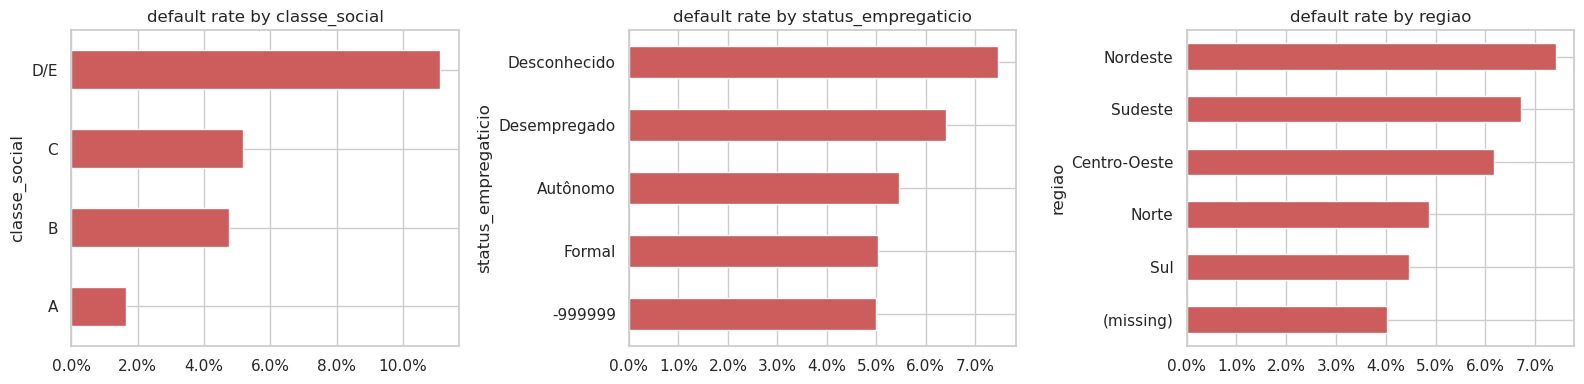

In [19]:
fig, axes = plt.subplots(1, len(cat_cols), figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    rate = (
        labeled.assign(**{col: labeled[col].fillna("(missing)")})
        .groupby(col)["OVER30M2"].mean().sort_values()
    )
    rate.plot.barh(ax=ax, color="indianred")
    ax.set_title(f"default rate by {col}")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## 8. Findings & next steps

**Findings**

1. **Grain**: neither table is unique on `uuid`. `perf` has 220,618 rows / 184,009 uuids (repeat applications across vintages). `feat` has 371,596 rows / 96,196 uuids — multiple feature snapshots per person, keyed by `REFERENCIA` (a date). A naive inner join explodes to **1.38M rows**, so the section-7 charts are directional only — the proper join must pick one feature snapshot per application (e.g. latest `REFERENCIA <= DATA`, avoiding future information / leakage).
2. **Coverage**: only 52.3% of `perf` uuids have any features (96,196); **47.7% have no Klavi data at all**. All `feat` uuids exist in `perf`.
3. **Target availability**: `OVER30M2` exists **only for `STATUS = Contratado`** (24,148 rows; 10.30% default rate). `Aprovado` (77k) and `Reprovado` (119k) have no performance → strong **selection bias / reject-inference** problem: any model trained on contracted clients only will not directly generalize to the through-the-door population.
4. **Vintage trend**: default rate drifts **upward** from ~8–10% (2024 vintages) to ~12.5% (202506). Could be real credit deterioration or immature performance in recent safras — need to confirm the performance window (over-30-days within first 2 months) is fully observed for the latest vintages.
5. **Missingness has structure**: `score_klavi_1`, `Renda`, `risco_aposta` are missing together in **91.3%** of feature rows (present only for ~32k rows — likely only where open-finance/transactional data was shared). `score_klavi_2` (10.8% missing) and `Capacidade Financeira` (12.5%) have much broader coverage — important for policy practicality.
6. **Sentinel / invalid values**: `score_klavi_1` has **-999999 sentinels** (min = -999999, real range looks like 0–100) and `Capacidade Financeira` has extreme negatives (min ≈ -1.09M). Must be cleaned to NaN before any analysis.
7. `DATA`/`REFERENCIA` are ISO-date strings → parse to datetime; `SAFRA` is float (e.g. 202408.0) → cast to int/period.

**Open questions for the client**

- Exact definition and observation window of `OVER30M2` — is performance mature for safras 202505–202506?
- What distinguishes `Aprovado` from `Contratado` (approved-not-taken)? Was the current policy using `score_klavi_2` already (would explain selection bias)?
- Why do 47.7% of applications have no Klavi features — consent funnel, integration date, or data extraction issue?
- What does each `REFERENCIA` snapshot represent, and which one is available *at decision time*?

**Next steps**

- `1.1` cleaning: sentinel → NaN, dtypes, dedup rule (one feature snapshot per application, point-in-time correct); write cleaned tables to `data/interim/`
- `2.0` feature analysis on the clean point-in-time joined sample: IV/WoE, correlation, stability by SAFRA (PSI)
- `3.0` scorecard / candidate policy rules + validation design (OOT split by SAFRA, selection-bias discussion)